# BU First Destination Survey (FDS) Analysis + Handshake Bridge + Student Outcome Analysis
**Data:** FDS_2020-2024_Employer_Outcomes_Anonymized.xlsx | 10,004 BU graduate outcomes (2019–2024)

**Contributors: Sviat Shevchenko (Track 1 FDS Analysis + Track 2 Handshake Bridge), Shaotai Hu (Track 3 Student Outcome Analysis), Abigail Merage, Tessa Thomas**

Last Updated: 3/24/2026

Documentation link: https://docs.google.com/document/d/1noKw36_t1GgOxWHFcByYh6V7X5I12J-5jIe-ArHE_l8/edit?usp=sharing

**Structure:**
- **Track 1** — Standalone FDS analysis: outcomes by college, major, industry, job function, demographics, geography, trends
- **Track 2** — Handshake bridge: compare EEIS-ranked employers vs actual BU graduate placement
- **Track 3** — Student outcome analysis: employer activity vs student hiring outcomes (Shaotai Hu)

> Note: FDS data has no employer_id so cannot be directly joined to Handshake. Track 2 uses manual name mapping for the top 20 Handshake employers. Track 3 uses a fuzzy name merge between ep_joined and outcomes.csv.

## Setup

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

# ---- File locations ----
# Update DATA_DIR to wherever your CSVs live.
DATA_DIR = ''

fds = pd.read_excel(os.path.join(DATA_DIR, 'FDS 2020-2024 Employer Outcomes (Anonymized).xlsx'))

# Clean graduation year
fds['grad_year'] = fds['Graduation Date'].str.extract(r'(\d{4})').astype(float).astype('Int64')

# Normalize gender
fds['gender_clean'] = fds['Student Gender'].replace({'Female': 'Woman', 'Male': 'Man'})

# Normalize domestic/international
fds['intl_clean'] = fds['Student Domestic/International Status'].replace({
    'Y': 'International', '?': 'Unknown'
})

# Load employer KPI from Milestone 2 output
employer_kpi = pd.read_csv(os.path.join(DATA_DIR, 'employer_kpi.csv'))

print(f'FDS rows: {len(fds):,}')
print(f'Years: {sorted(fds["grad_year"].dropna().unique().tolist())}')
print(f'employer_kpi rows: {len(employer_kpi):,}')
print(f'employer_kpi columns: {employer_kpi.columns.tolist()}')

FDS rows: 10,004
Years: [2019, 2020, 2021, 2022, 2023, 2024]
employer_kpi rows: 56,089
employer_kpi columns: ['employer_id', 'employer_name', 'employer_type', 'total_jobs', 'total_applications', 'JAY', 'total_events_dedup', 'total_attendees_dedup', 'EAY', 'EEB', 'EEC', 'ACI', 'avg_salary_mid', 'SSI', 'EEIS']


---
# Track 1 — Standalone FDS Analysis
Examines BU graduate employment outcomes independently of Handshake data.

**Contributor: Sviat Shevchenko**

## 1A. Top Hiring Employers by Volume

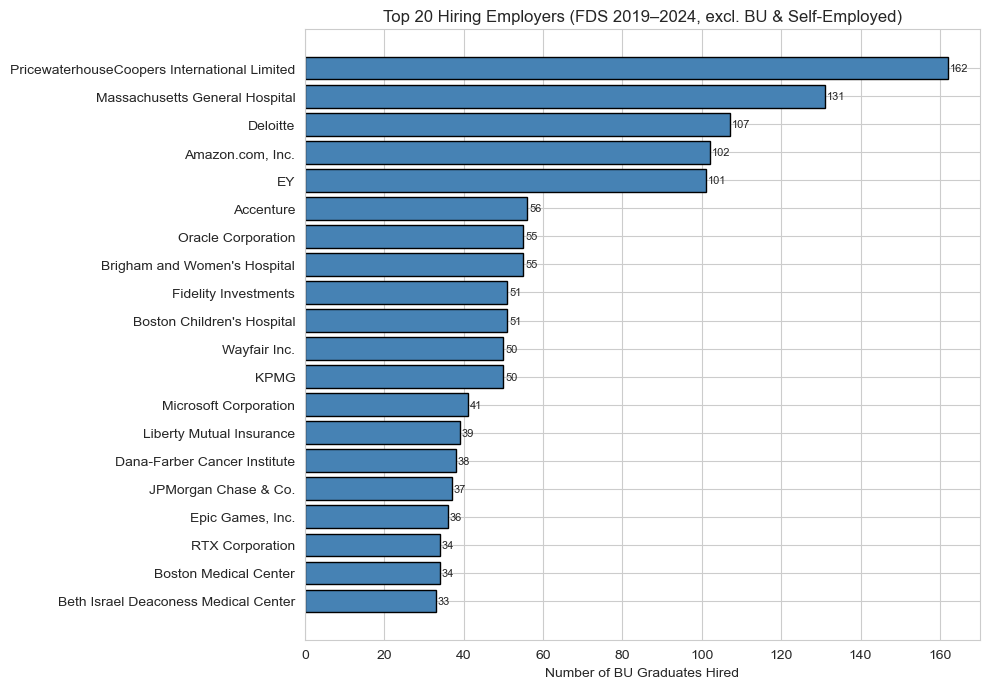

Employer Name
PricewaterhouseCoopers International Limited    162
Massachusetts General Hospital                  131
Deloitte                                        107
Amazon.com, Inc.                                102
EY                                              101
Accenture                                        56
Oracle Corporation                               55
Brigham and Women's Hospital                     55
Fidelity Investments                             51
Boston Children's Hospital                       51
Wayfair Inc.                                     50
KPMG                                             50
Microsoft Corporation                            41
Liberty Mutual Insurance                         39
Dana-Farber Cancer Institute                     38
JPMorgan Chase & Co.                             37
Epic Games, Inc.                                 36
RTX Corporation                                  34
Boston Medical Center                            3

In [4]:
# Top hiring employers — exclude BU itself and unknowns for external view
exclude = ['boston university', 'unknown', 'self-employed']
top_emp = (
    fds[~fds['Employer Name'].str.lower().fillna('').isin(exclude)]
    ['Employer Name'].value_counts().head(20)
)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_emp.index[::-1], top_emp.values[::-1], color='steelblue', edgecolor='black')
for i, v in enumerate(top_emp.values[::-1]):
    ax.text(v + 0.5, i, str(v), va='center', fontsize=8)
ax.set_xlabel('Number of BU Graduates Hired')
ax.set_title('Top 20 Hiring Employers (FDS 2019–2024, excl. BU & Self-Employed)')
plt.tight_layout()
plt.show()

print(top_emp)

## 1B. Outcomes by Industry

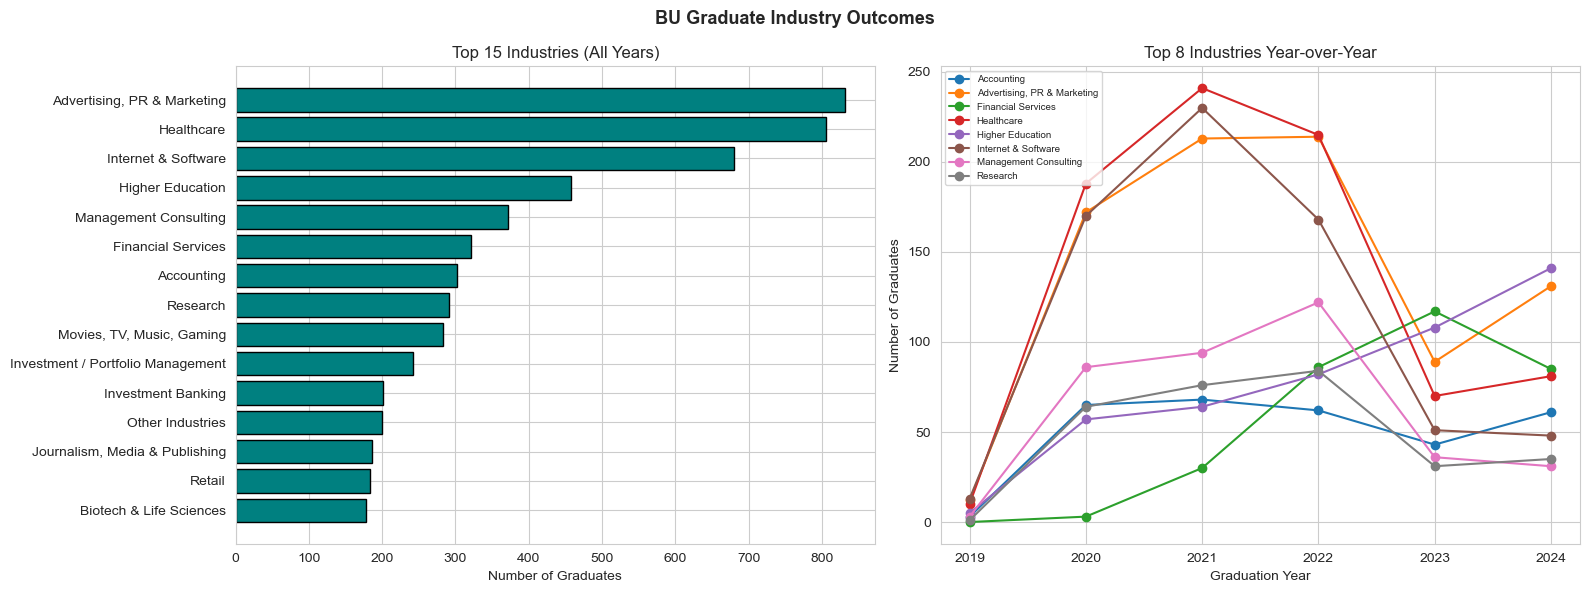

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Overall top industries
top_ind = fds['Employer Industry'].value_counts().head(15)
axes[0].barh(top_ind.index[::-1], top_ind.values[::-1], color='teal', edgecolor='black')
axes[0].set_xlabel('Number of Graduates')
axes[0].set_title('Top 15 Industries (All Years)')

# Industry by year (top 8)
top8_ind = fds['Employer Industry'].value_counts().head(8).index
ind_year = fds[fds['Employer Industry'].isin(top8_ind)]\
    .groupby(['grad_year', 'Employer Industry']).size().unstack(fill_value=0)
ind_year.plot(ax=axes[1], marker='o')
axes[1].set_xlabel('Graduation Year')
axes[1].set_ylabel('Number of Graduates')
axes[1].set_title('Top 8 Industries Year-over-Year')
axes[1].legend(fontsize=7, loc='upper left')

plt.suptitle('BU Graduate Industry Outcomes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 1C. Outcomes by Job Function

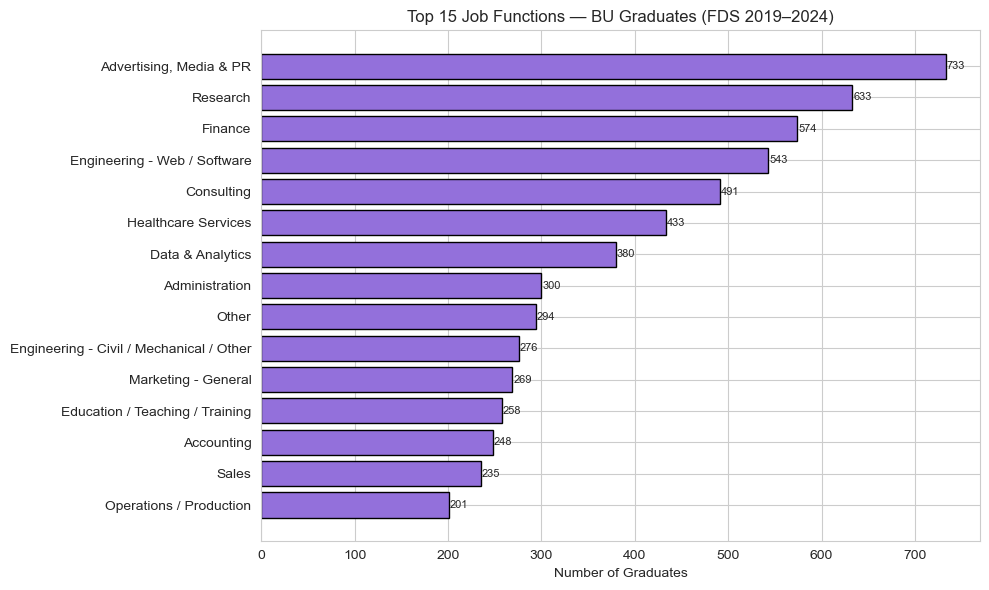

In [6]:
top_jf = fds['Job Function'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_jf.index[::-1], top_jf.values[::-1], color='mediumpurple', edgecolor='black')
for i, v in enumerate(top_jf.values[::-1]):
    ax.text(v + 1, i, str(v), va='center', fontsize=8)
ax.set_xlabel('Number of Graduates')
ax.set_title('Top 15 Job Functions — BU Graduates (FDS 2019–2024)')
plt.tight_layout()
plt.show()

## 1D. Outcomes by College and Major

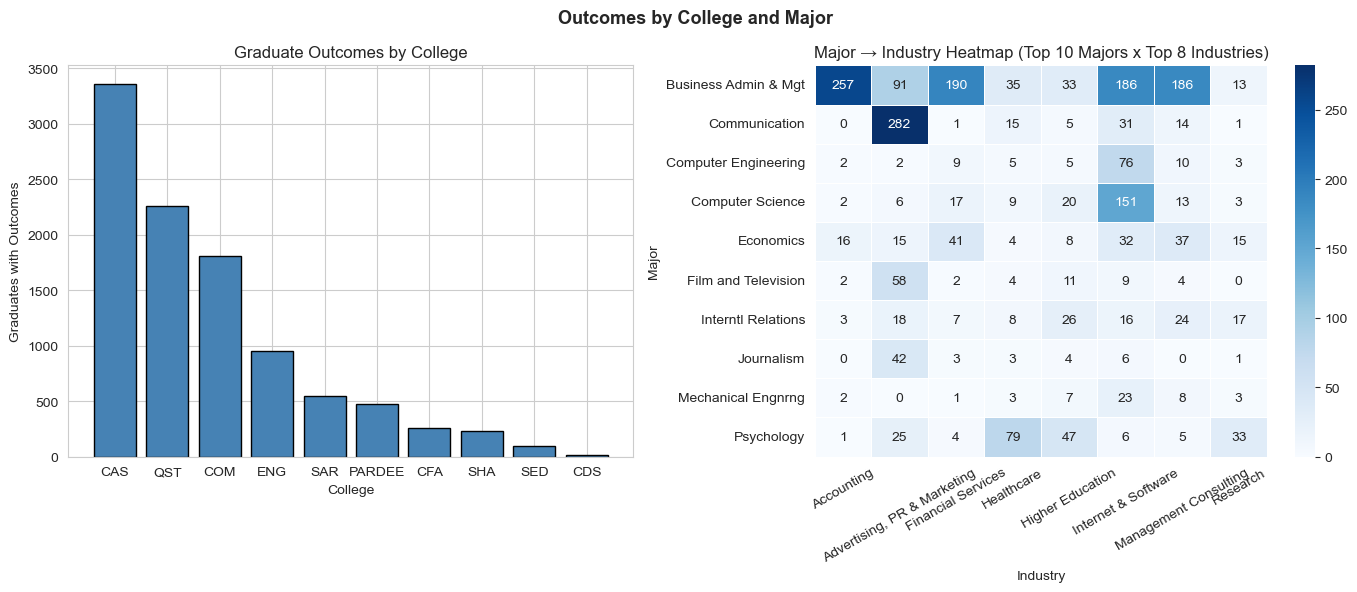

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# By college
college_counts = fds['Graduation Degree College_1'].value_counts()
axes[0].bar(college_counts.index, college_counts.values, color='steelblue', edgecolor='black')
axes[0].set_xlabel('College')
axes[0].set_ylabel('Graduates with Outcomes')
axes[0].set_title('Graduate Outcomes by College')

# Top major → top industry heatmap
top10_majors = fds['GRAD MAJOR #1'].value_counts().head(10).index
top8_industries = fds['Employer Industry'].value_counts().head(8).index
heatmap_data = fds[
    fds['GRAD MAJOR #1'].isin(top10_majors) &
    fds['Employer Industry'].isin(top8_industries)
].groupby(['GRAD MAJOR #1', 'Employer Industry']).size().unstack(fill_value=0)

sns.heatmap(heatmap_data, ax=axes[1], cmap='Blues', annot=True, fmt='d', linewidths=0.5)
axes[1].set_title('Major → Industry Heatmap (Top 10 Majors x Top 8 Industries)')
axes[1].set_xlabel('Industry')
axes[1].set_ylabel('Major')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle('Outcomes by College and Major', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 1E. Demographics Breakdown
> Note: Gender has two coding schemes in the raw data (Man/Woman and Male/Female). Normalized to Man/Woman. Domestic/International '?' treated as Unknown.

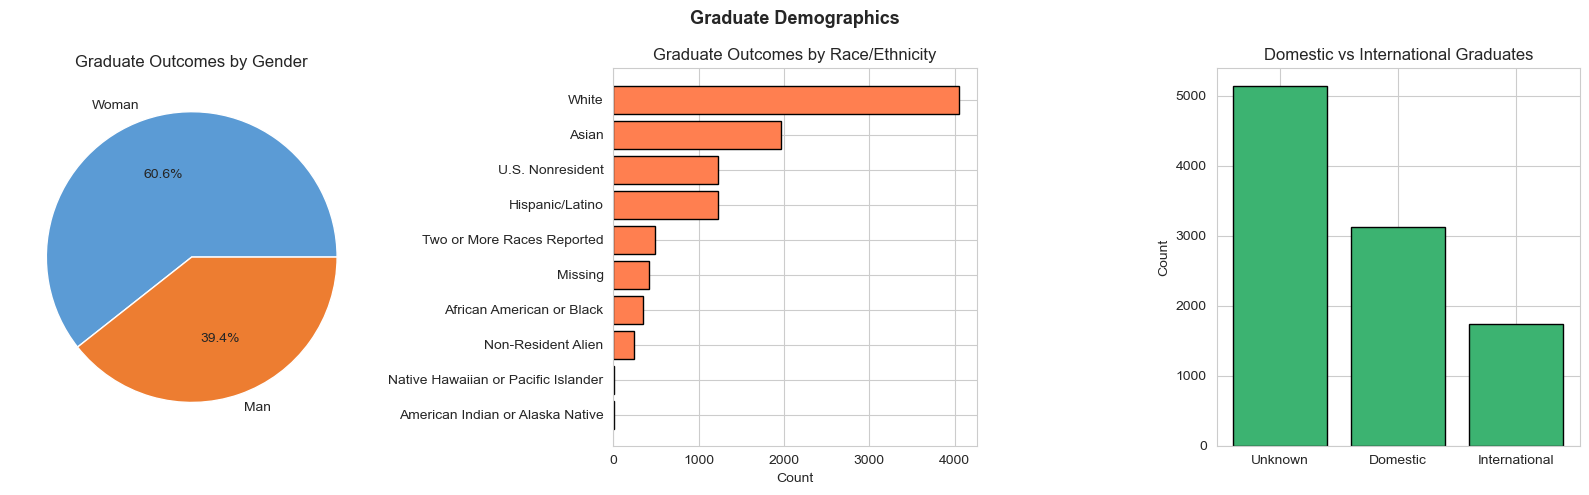

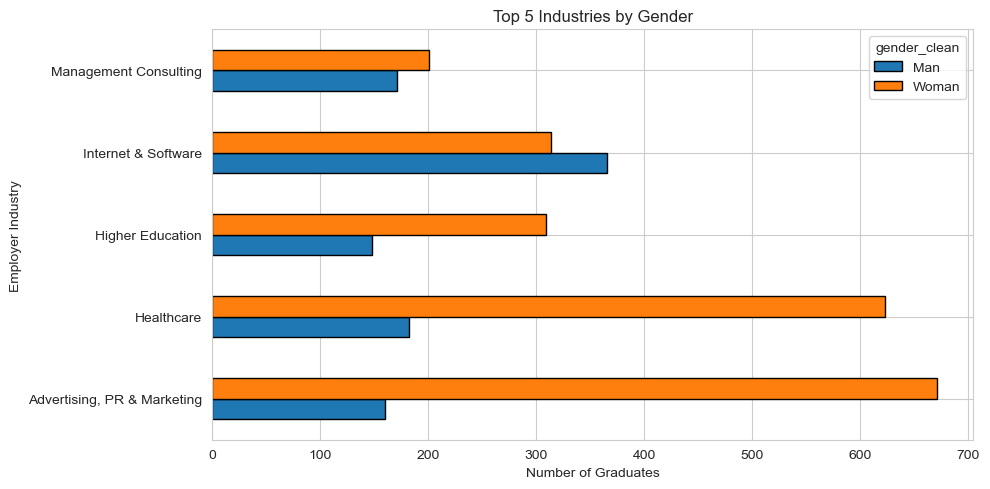

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Gender
gender_counts = fds['gender_clean'].value_counts()
axes[0].pie(gender_counts.values, labels=gender_counts.index,
            autopct='%1.1f%%', colors=['#5B9BD5','#ED7D31','#A9D18E'])
axes[0].set_title('Graduate Outcomes by Gender')

# Race/Ethnicity
race = fds['Student IPEDS Race Ethnicity'].value_counts()
axes[1].barh(race.index[::-1], race.values[::-1], color='coral', edgecolor='black')
axes[1].set_xlabel('Count')
axes[1].set_title('Graduate Outcomes by Race/Ethnicity')

# Domestic vs International
intl_counts = fds['intl_clean'].value_counts()
axes[2].bar(intl_counts.index, intl_counts.values, color='mediumseagreen', edgecolor='black')
axes[2].set_title('Domestic vs International Graduates')
axes[2].set_ylabel('Count')

plt.suptitle('Graduate Demographics', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Industry by gender
top5_ind = fds['Employer Industry'].value_counts().head(5).index
gender_ind = fds[fds['Employer Industry'].isin(top5_ind)]\
    .groupby(['Employer Industry','gender_clean']).size().unstack(fill_value=0)
gender_ind.plot(kind='barh', figsize=(10,5), edgecolor='black')
plt.title('Top 5 Industries by Gender')
plt.xlabel('Number of Graduates')
plt.tight_layout()
plt.show()

## 1F. Geographic Distribution

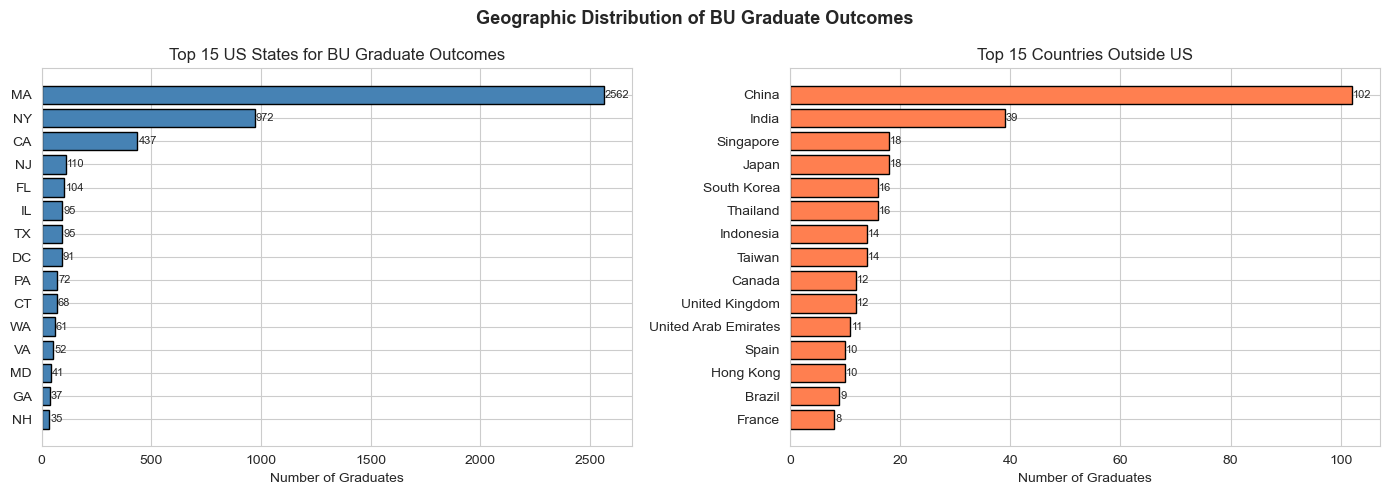

Graduates staying in US: 5,129 (92.5%)
Graduates going abroad: 417


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top US states
top_states = fds[fds['Outcome Country'] == 'United States of America']\
    ['Outcome State'].value_counts().head(15)
axes[0].barh(top_states.index[::-1], top_states.values[::-1], color='steelblue', edgecolor='black')
axes[0].set_xlabel('Number of Graduates')
axes[0].set_title('Top 15 US States for BU Graduate Outcomes')
for i, v in enumerate(top_states.values[::-1]):
    axes[0].text(v + 5, i, str(v), va='center', fontsize=8)

# Top countries (excluding US)
top_countries = fds[fds['Outcome Country'] != 'United States of America']\
    ['Outcome Country'].value_counts().head(15)
axes[1].barh(top_countries.index[::-1], top_countries.values[::-1], color='coral', edgecolor='black')
axes[1].set_xlabel('Number of Graduates')
axes[1].set_title('Top 15 Countries Outside US')
for i, v in enumerate(top_countries.values[::-1]):
    axes[1].text(v + 0.2, i, str(v), va='center', fontsize=8)

plt.suptitle('Geographic Distribution of BU Graduate Outcomes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

us_pct = (fds['Outcome Country'] == 'United States of America').sum()
print(f'Graduates staying in US: {us_pct:,} ({100*us_pct/fds["Outcome Country"].notna().sum():.1f}%)')
print(f'Graduates going abroad: {fds["Outcome Country"].notna().sum() - us_pct:,}')

## 1G. Year-over-Year Trends (2019–2024)

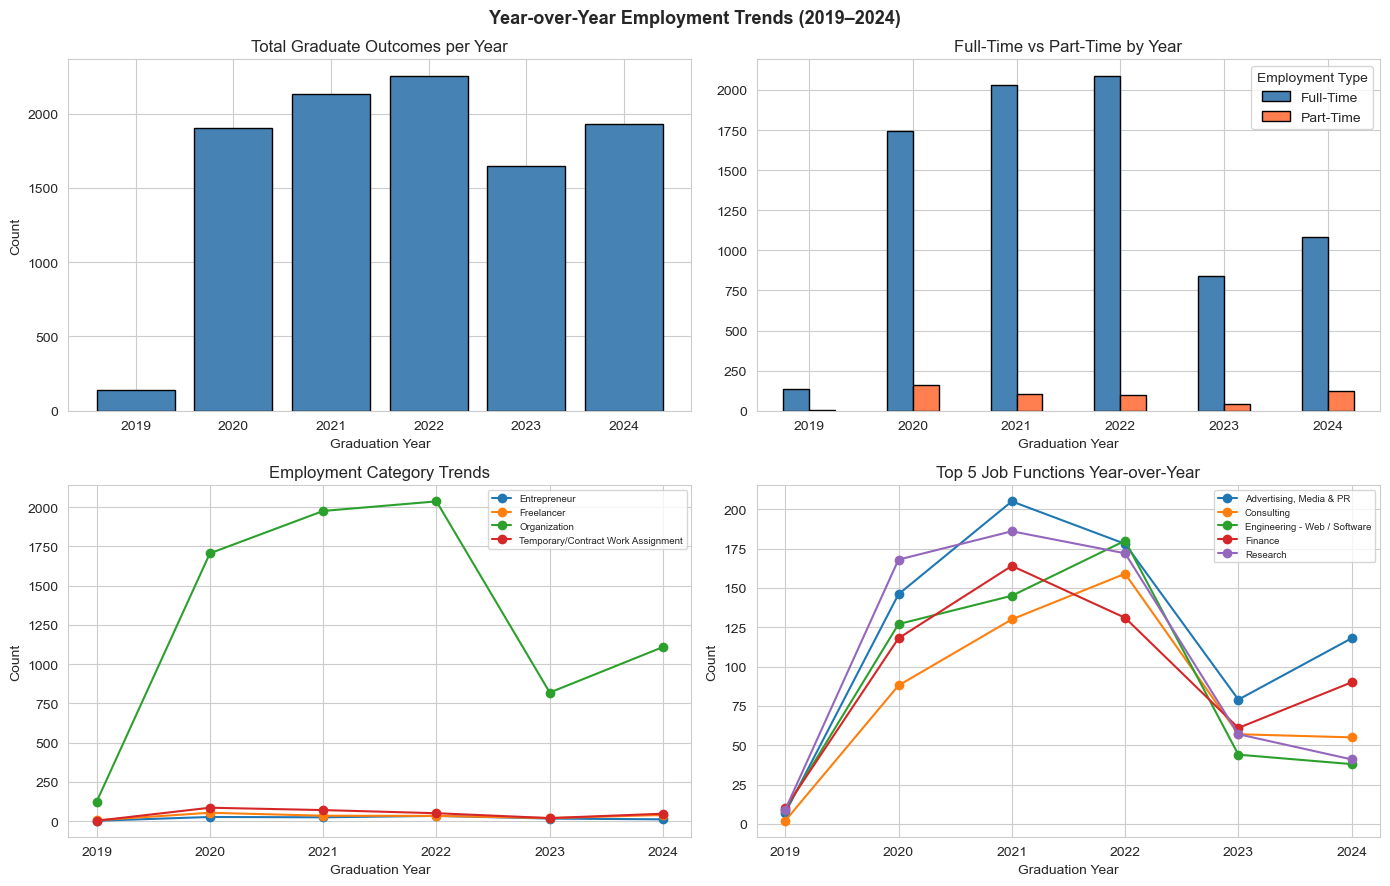

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Total outcomes by year
by_year = fds.groupby('grad_year').size()
axes[0,0].bar(by_year.index, by_year.values, color='steelblue', edgecolor='black')
axes[0,0].set_title('Total Graduate Outcomes per Year')
axes[0,0].set_xlabel('Graduation Year')
axes[0,0].set_ylabel('Count')

# Full-time vs part-time by year
emp_type_year = fds.groupby(['grad_year','Employment Type']).size().unstack(fill_value=0)
emp_type_year.plot(kind='bar', ax=axes[0,1], edgecolor='black', color=['steelblue','coral'])
axes[0,1].set_title('Full-Time vs Part-Time by Year')
axes[0,1].set_xlabel('Graduation Year')
axes[0,1].tick_params(axis='x', rotation=0)

# Employment category by year
top_cats = ['Organization', 'Temporary/Contract Work Assignment', 'Freelancer', 'Entrepreneur']
cat_year = fds[fds['Employment Category'].isin(top_cats)]\
    .groupby(['grad_year','Employment Category']).size().unstack(fill_value=0)
cat_year.plot(ax=axes[1,0], marker='o')
axes[1,0].set_title('Employment Category Trends')
axes[1,0].set_xlabel('Graduation Year')
axes[1,0].set_ylabel('Count')
axes[1,0].legend(fontsize=7)

# Top job functions by year (top 5)
top5_jf = fds['Job Function'].value_counts().head(5).index
jf_year = fds[fds['Job Function'].isin(top5_jf)]\
    .groupby(['grad_year','Job Function']).size().unstack(fill_value=0)
jf_year.plot(ax=axes[1,1], marker='o')
axes[1,1].set_title('Top 5 Job Functions Year-over-Year')
axes[1,1].set_xlabel('Graduation Year')
axes[1,1].set_ylabel('Count')
axes[1,1].legend(fontsize=7)

plt.suptitle('Year-over-Year Employment Trends (2019–2024)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
# Track 2 — Handshake Bridge Analysis
Compares employers ranked highly by EEIS on Handshake against actual BU graduate placement in FDS.

**Contributor: Sviat Shevchenko**

**Method:** Manual name mapping of top 20 Handshake employers to FDS employer names. No programmatic join — FDS has no employer_id primary key and names are inconsistent across datasets.

**Key question:** Do employers that engage heavily on Handshake actually hire BU graduates at scale? Where the answer is no, those employers represent targeting opportunities for CCD.

## 2A. EEIS Rank vs FDS Hire Count — Bridge Table

In [12]:
# Load employer KPI table from Milestone 2 notebook output
employer_kpi = pd.read_csv(os.path.join(DATA_DIR, 'employer_kpi.csv'))

# Rank employers by EEIS
employer_kpi['eeis_rank'] = employer_kpi['EEIS'].rank(ascending=False, method='min').astype(int)

# Take top 20 by EEIS rank
top20 = employer_kpi.nsmallest(20, 'eeis_rank')[['employer_name', 'EEIS', 'eeis_rank']].copy()

# FDS search string — normalize employer name for fuzzy search
top20['fds_search'] = (
    top20['employer_name']
    .str.lower()
    .str.replace(r'\s+(llp|inc|corp|ltd|co|llc|&|company)\.?$', '', regex=True)
    .str.strip()
)

# Count FDS hires per employer using normalized name
fds_lower = fds['Employer Name'].str.lower().fillna('')
top20['fds_hires'] = top20['fds_search'].apply(
    lambda s: fds_lower.str.contains(s, na=False).sum()
)

# FDS hire rank
top20['fds_hire_rank'] = top20['fds_hires'].rank(ascending=False, method='min').astype(int)

# Rank gap: positive = hires more than engagement rank, negative = engagement higher than hires
top20['rank_gap'] = top20['fds_hire_rank'] - top20['eeis_rank']

# Flag
top20['flag'] = top20['rank_gap'].apply(
    lambda x: 'Targeting Opportunity' if x <= -5 else ('Strong Converter' if x >= 5 else 'Balanced')
)

bridge = top20.copy()

display(bridge[['employer_name', 'EEIS', 'eeis_rank', 'fds_hires', 'fds_hire_rank', 'rank_gap', 'flag']]
        .sort_values('eeis_rank'))

,employer_name,EEIS,eeis_rank,fds_hires,fds_hire_rank,rank_gap,flag
135,ey,0.564389,1,306,2,1,Balanced
1731,jpmorganchase,0.443114,2,1,15,13,Strong Converter
2461,amazon,0.434246,3,107,4,1,Balanced
4947,pwc,0.428640,4,1,15,11,Strong Converter
759,morgan stanley,0.405373,5,15,11,6,Strong Converter
921,mckinsey & company,0.400480,6,12,12,6,Strong Converter
838,goldman sachs,0.398874,7,32,8,1,Balanced
32,kpmg llp,0.368375,8,53,5,-3,Balanced
728,capital one,0.327816,9,23,10,1,Balanced
46,deloitte,0.317176,10,112,3,-7,Targeting Opportunity


## 2B. Engagement vs Placement Comparison

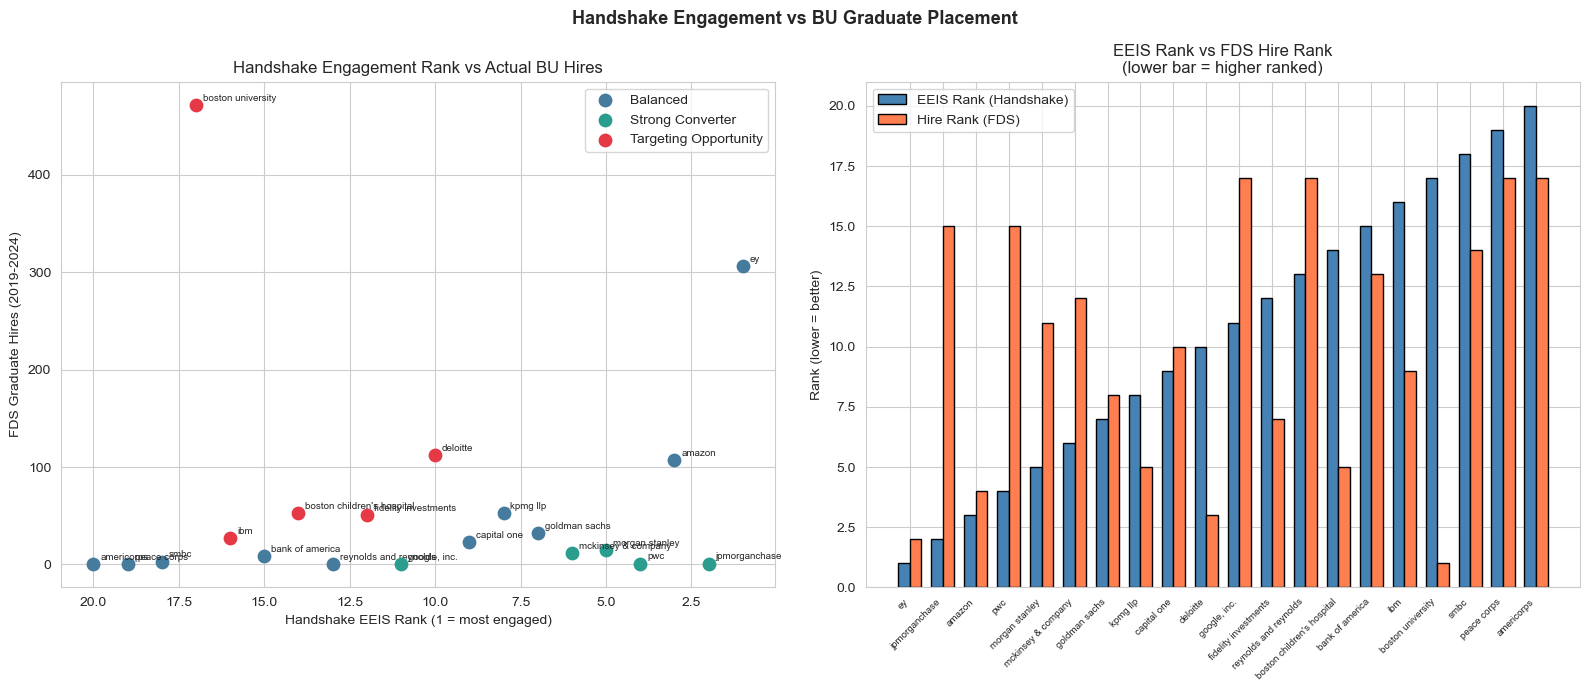

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: EEIS rank vs FDS hires scatter
colors = {'Targeting Opportunity': '#e63946', 'Strong Converter': '#2a9d8f', 'Balanced': '#457b9d'}
for flag, grp in bridge.groupby('flag'):
    axes[0].scatter(grp['eeis_rank'], grp['fds_hires'],
                    label=flag, color=colors[flag], s=80, zorder=3)
    for _, row in grp.iterrows():
        axes[0].annotate(row['employer_name'],
                         (row['eeis_rank'], row['fds_hires']),
                         textcoords='offset points', xytext=(5, 3), fontsize=7)

axes[0].set_xlabel('Handshake EEIS Rank (1 = most engaged)')
axes[0].set_ylabel('FDS Graduate Hires (2019-2024)')
axes[0].set_title('Handshake Engagement Rank vs Actual BU Hires')
axes[0].legend()
axes[0].invert_xaxis()

# Right: side-by-side rank comparison
bridge_sorted = bridge.sort_values('eeis_rank')
x = range(len(bridge_sorted))
width = 0.35

axes[1].bar([i - width/2 for i in x], bridge_sorted['eeis_rank'],
            width, label='EEIS Rank (Handshake)', color='steelblue', edgecolor='black')
axes[1].bar([i + width/2 for i in x], bridge_sorted['fds_hire_rank'],
            width, label='Hire Rank (FDS)', color='coral', edgecolor='black')
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(bridge_sorted['employer_name'], rotation=45, ha='right', fontsize=7)
axes[1].set_ylabel('Rank (lower = better)')
axes[1].set_title('EEIS Rank vs FDS Hire Rank\n(lower bar = higher ranked)')
axes[1].legend()

plt.suptitle('Handshake Engagement vs BU Graduate Placement', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 2C. CCD Targeting Opportunities
Employers flagged as **Targeting Opportunities** rank high on Handshake engagement (EEIS) but produce relatively few BU graduate hires. These are employers already investing in campus presence — CCD could work to convert that engagement into actual placement outcomes.

**Strong Converters** are employers where FDS hire rank significantly exceeds EEIS rank — they hire BU graduates at high rates relative to their Handshake engagement, suggesting off-platform or relationship-driven hiring that Handshake doesn't fully capture.

In [17]:
# Targeting opportunities — high engagement, low conversion
targeting = bridge[bridge['flag'] == 'Targeting Opportunity'].sort_values('eeis_rank')
converters = bridge[bridge['flag'] == 'Strong Converter'].sort_values('fds_hires', ascending=False)

print('=== TARGETING OPPORTUNITIES (High EEIS, Low FDS Hires) ===')
print('These employers are active on Handshake but under-convert to BU placements.')
display(targeting[['employer_name', 'eeis_rank', 'fds_hires', 'fds_hire_rank', 'rank_gap']])

print('\n=== STRONG CONVERTERS (High FDS Hires relative to EEIS Rank) ===')
print('These employers hire BU graduates at high rates beyond Handshake engagement alone.')
display(converters[['employer_name', 'eeis_rank', 'fds_hires', 'fds_hire_rank', 'rank_gap']])

# Breakdown: what functions/industries do hires go into at top converters
if len(converters) > 0:
    top_converter = converters.iloc[0]['fds_search']
    converter_hires = fds[fds['Employer Name'].str.lower().str.contains(top_converter, na=False)]
    print(f'\nJob functions for top converter ({converters.iloc[0]["employer_name"]}):')
    print(converter_hires['Job Function'].value_counts().head(8))

=== TARGETING OPPORTUNITIES (High EEIS, Low FDS Hires) ===
These employers are active on Handshake but under-convert to BU placements.


,employer_name,eeis_rank,fds_hires,fds_hire_rank,rank_gap
46,deloitte,10,112,3,-7
566,fidelity investments,12,51,7,-5
26235,boston children's hospital,14,53,5,-9
56,ibm,16,27,9,-7
6713,boston university,17,472,1,-16



=== STRONG CONVERTERS (High FDS Hires relative to EEIS Rank) ===
These employers hire BU graduates at high rates beyond Handshake engagement alone.


,employer_name,eeis_rank,fds_hires,fds_hire_rank,rank_gap
759,morgan stanley,5,15,11,6
921,mckinsey & company,6,12,12,6
1731,jpmorganchase,2,1,15,13
4947,pwc,4,1,15,11
411,"google, inc.",11,0,17,6



Job functions for top converter (morgan stanley):
Job Function
Finance                       9
Legal                         1
Other                         1
Customer/Technical Support    1
Information Technology        1
Name: count, dtype: int64


## 2D. FDS Profile for Top Handshake Employers
For each matched employer, shows what BU graduates actually do there — job function, major, college, and graduation year trend.

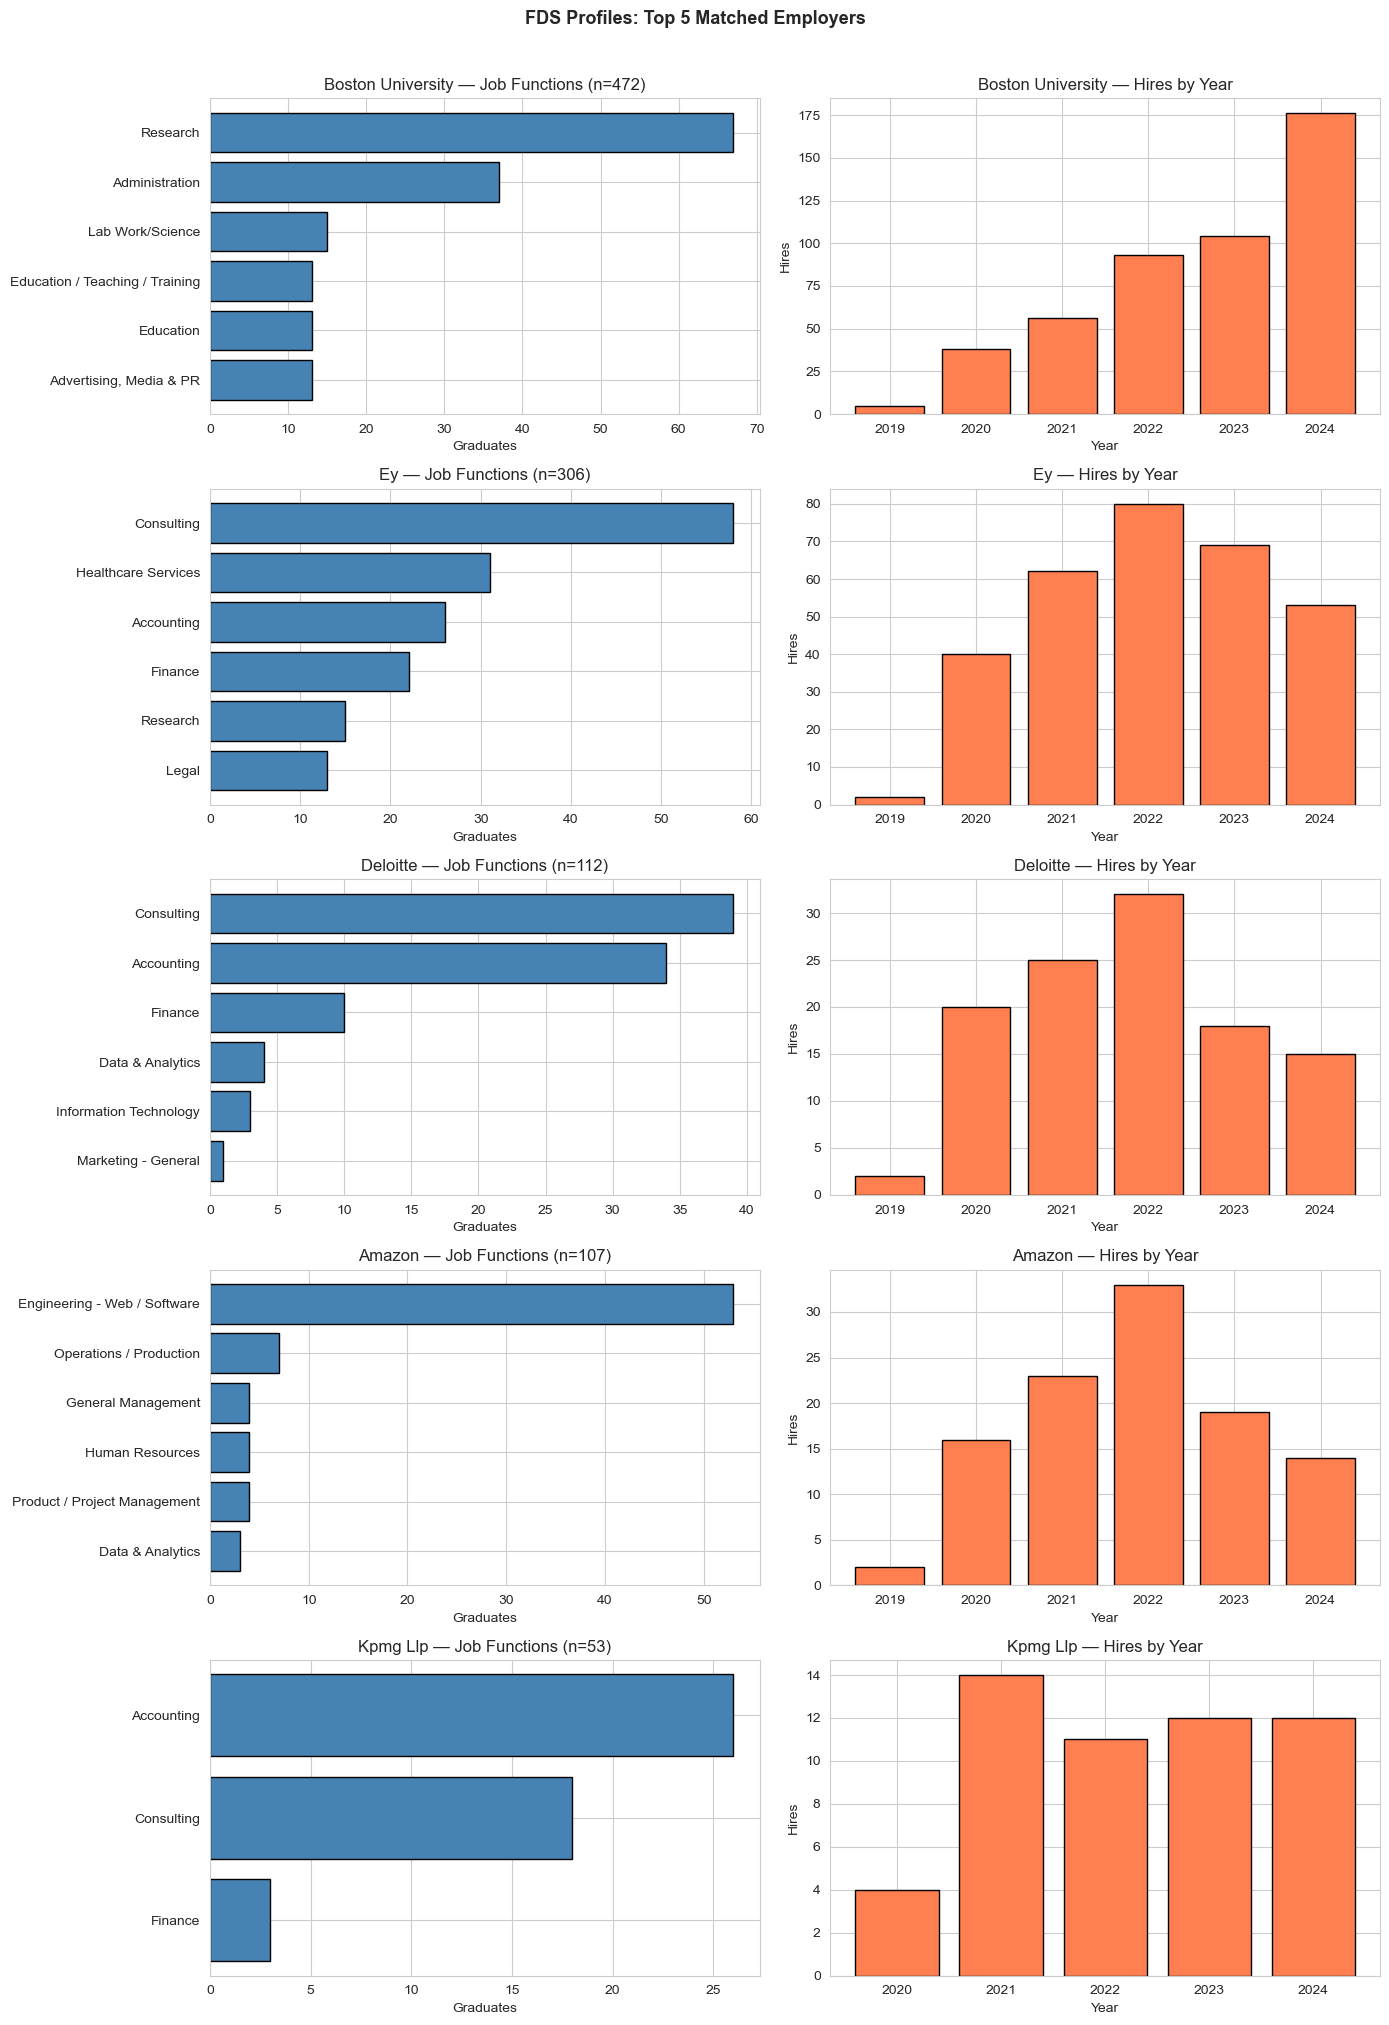

In [19]:
# Pick top 5 matched employers by FDS hires for detailed profile
top5_bridge = bridge.nlargest(5, 'fds_hires')

fig, axes = plt.subplots(len(top5_bridge), 2, figsize=(14, 4*len(top5_bridge)))

for idx, (_, row) in enumerate(top5_bridge.iterrows()):
    emp_fds = fds[fds['Employer Name'].str.lower().str.contains(row['fds_search'], na=False)]

    # Job function
    jf = emp_fds['Job Function'].value_counts().head(6)
    axes[idx, 0].barh(jf.index[::-1], jf.values[::-1], color='steelblue', edgecolor='black')
    axes[idx, 0].set_title(f"{row['employer_name'].title()} — Job Functions (n={len(emp_fds)})")
    axes[idx, 0].set_xlabel('Graduates')

    # Trend by year
    yr = emp_fds.groupby('grad_year').size()
    axes[idx, 1].bar(yr.index, yr.values, color='coral', edgecolor='black')
    axes[idx, 1].set_title(f"{row['employer_name'].title()} — Hires by Year")
    axes[idx, 1].set_xlabel('Year')
    axes[idx, 1].set_ylabel('Hires')

plt.suptitle('FDS Profiles: Top 5 Matched Employers', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
# Track 3 — Student Outcome Analysis
**Contributor: Shaotai Hu**

Joins Handshake employer activity with FDS student outcomes to analyze relationships between employer engagement on Handshake and actual BU student hiring outcomes.

Documentation: https://docs.google.com/document/d/1noKw36_t1GgOxWHFcByYh6V7X5I12J-5jIe-ArHE_l8/edit?usp=sharing

/var/folders/hv/tcqdmtjd09j4hgvm2929vjbh0000gn/T/ipykernel_50363/3136614652.py:11: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  ep_joined = pd.read_csv(os.path.join(DATA_DIR, "ep_joined.csv"))


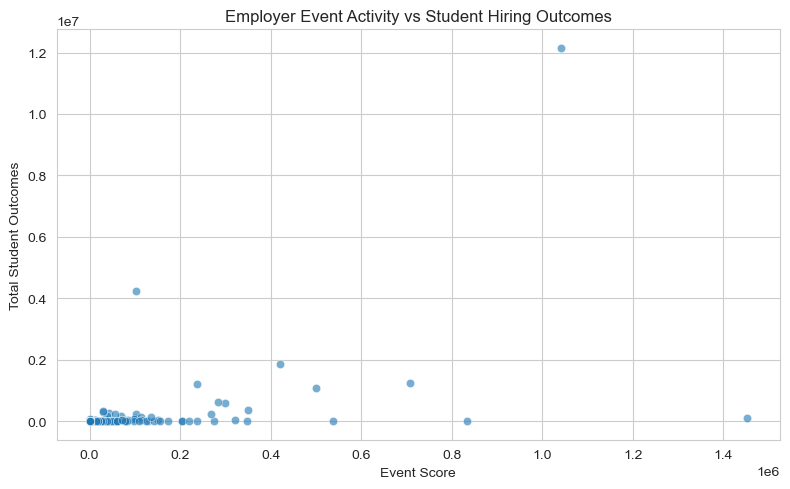

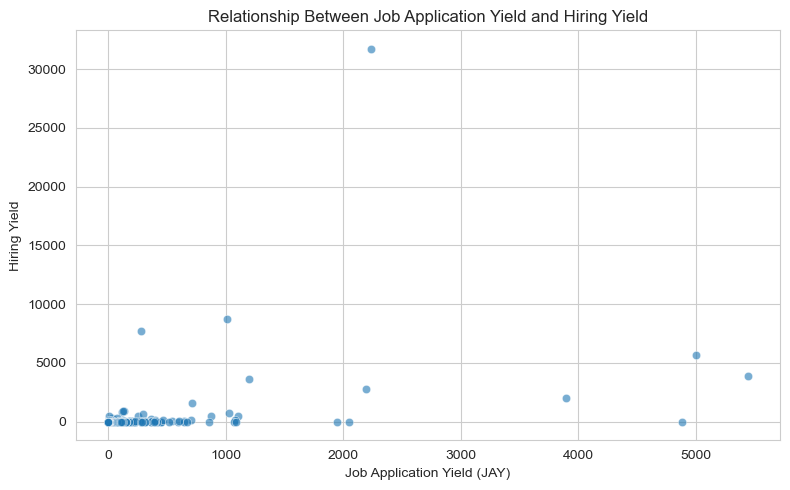

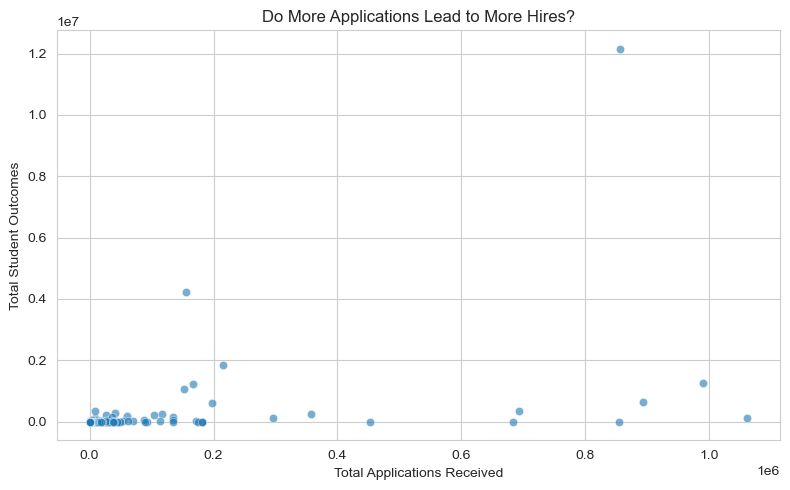

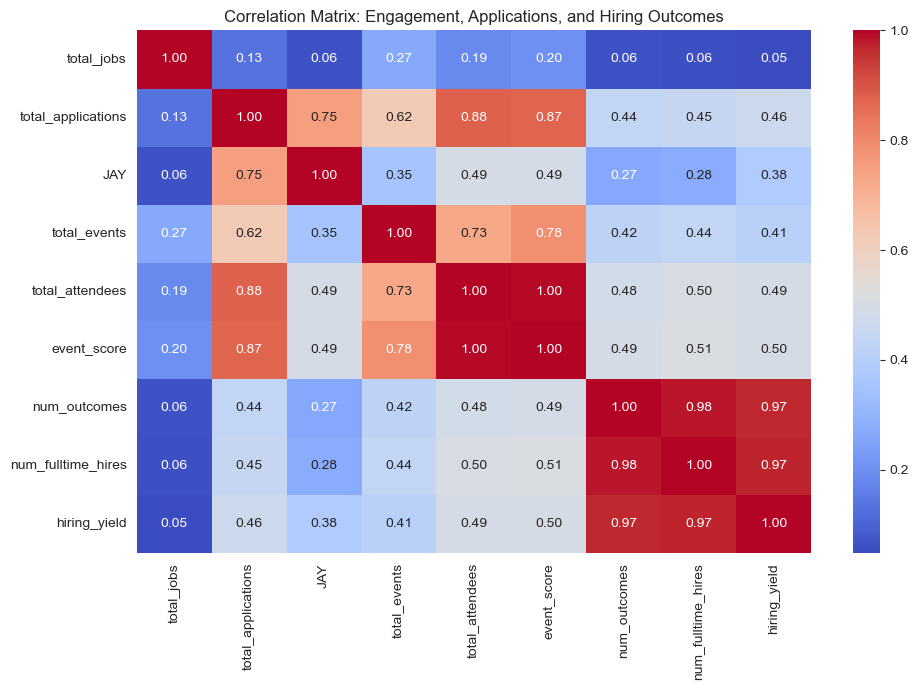

In [3]:
# 1. Imports & Setup
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

# 2. Load Data
DATA_DIR = ""   
ep_joined = pd.read_csv(os.path.join(DATA_DIR, "ep_joined.csv"))
outcomes = pd.read_csv(os.path.join(DATA_DIR, "outcomes.csv"))

# 3. Clean & Prepare Keys

# Standardize employer name fields for merging
ep_joined['employer_name_clean'] = (
    ep_joined['employer_name']
    .astype(str)
    .str.strip()
    .str.lower()
)

outcomes['Employer Name Clean'] = (
    outcomes['Employer Name']
    .astype(str)
    .str.strip()
    .str.lower()
)

# 4. Merge Without Double Counting

# Aggregate outcomes to employer level
outcomes_employer = outcomes.groupby('Employer Name Clean').agg({
    'Outcome': 'count',   
    'Employment Category': lambda x: (x == "Organization").sum(),
    'Employment Type': lambda x: (x == "Full-Time").sum()
}).rename(columns={
    'Outcome': 'num_outcomes',
    'Employment Category': 'num_org_hires',
    'Employment Type': 'num_fulltime_hires'
})

# Merge aggregated outcomes onto ep_joined
ep_outcomes = ep_joined.merge(
    outcomes_employer,
    how='left',
    left_on='employer_name_clean',
    right_on='Employer Name Clean'
)

# Fill missing values
ep_outcomes[['num_outcomes','num_org_hires','num_fulltime_hires']] = \
    ep_outcomes[['num_outcomes','num_org_hires','num_fulltime_hires']].fillna(0)

# Save new file
ep_outcomes.to_csv(os.path.join(DATA_DIR, "ep_outcomes.csv"), index=False)

# 5. Engineer New Variables

# Employer-level aggregation
employer_metrics = ep_outcomes.groupby('employer_id').agg({
    'jobs_id': 'nunique',
    'applications_count': 'sum',
    'events_name': lambda x: x.notna().sum(),
    'student_attendees_count': 'sum',
    'num_outcomes': 'sum',
    'num_fulltime_hires': 'sum'
})

employer_metrics = employer_metrics.rename(columns={
    'jobs_id': 'total_jobs',
    'applications_count': 'total_applications',
    'events_name': 'total_events',
    'student_attendees_count': 'total_attendees'
})

# Job Application Yield
employer_metrics['JAY'] = employer_metrics['total_applications'] / employer_metrics['total_jobs']

# Event Score
employer_metrics['event_score'] = employer_metrics['total_events'] + employer_metrics['total_attendees']

# Hiring Yield
employer_metrics['hiring_yield'] = employer_metrics['num_outcomes'] / employer_metrics['total_jobs']

# 6. Visualizations

# Plot 1: Event Score vs Hiring Outcomes
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=employer_metrics,
    x='event_score',
    y='num_outcomes',
    alpha=0.6
)
plt.xlabel("Event Score")
plt.ylabel("Total Student Outcomes")
plt.title("Employer Event Activity vs Student Hiring Outcomes")
plt.tight_layout()
plt.show()

# Plot 2: JAY vs Hiring Yield
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=employer_metrics,
    x='JAY',
    y='hiring_yield',
    alpha=0.6
)
plt.xlabel("Job Application Yield (JAY)")
plt.ylabel("Hiring Yield")
plt.title("Relationship Between Job Application Yield and Hiring Yield")
plt.tight_layout()
plt.show()

# Plot 3: Applications vs Outcomes
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=employer_metrics,
    x='total_applications',
    y='num_outcomes',
    alpha=0.6
)
plt.xlabel("Total Applications Received")
plt.ylabel("Total Student Outcomes")
plt.title("Do More Applications Lead to More Hires?")
plt.tight_layout()
plt.show()

# Plot 4: Correlation Heatmap
corr_cols = [
    'total_jobs','total_applications','JAY',
    'total_events','total_attendees','event_score',
    'num_outcomes','num_fulltime_hires','hiring_yield'
]

plt.figure(figsize=(10,7))
sns.heatmap(
    employer_metrics[corr_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix: Engagement, Applications, and Hiring Outcomes")
plt.tight_layout()
plt.show()